# NumPy Tutorial

AI Example 코드에서 실제로 사용된 NumPy 기능들을 학습할 수 있도록 구성되었습니다.

## 목차
1. [NumPy 기본 개념](#numpy-기본-개념)
2. [배열 생성과 초기화](#배열-생성과-초기화)
3. [배열 연산과 수학 함수](#배열-연산과-수학-함수)
4. [배열 인덱싱과 슬라이싱](#배열-인덱싱과-슬라이싱)
5. [배열 모양 변경](#배열-모양-변경)
6. [선형대수 연산](#선형대수-연산)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print(f"NumPy 버전: {np.__version__}")

NumPy 버전: 2.2.5


## 1. NumPy 기본 개념

NumPy는 Python에서 과학적 컴퓨팅을 위한 핵심 라이브러리입니다. 특히 AI/ML 프로젝트에서 다차원 배열 처리에 필수적입니다.

In [2]:
# 기본 배열 생성
arr_1d = np.array([1, 2, 3, 4, 5])
arr_2d = np.array([[1, 2, 3], [4, 5, 6]])

print("1D array:", arr_1d)
print("2D array:")
print(arr_2d)
print("\nArray information:")
print(f"1D array shape: {arr_1d.shape}")
print(f"2D array shape: {arr_2d.shape}")
print(f"1D array ndim: {arr_1d.ndim}")
print(f"2D array ndim: {arr_2d.ndim}")

1D array: [1 2 3 4 5]
2D array:
[[1 2 3]
 [4 5 6]]

Array information:
1D array shape: (5,)
2D array shape: (2, 3)
1D array ndim: 1
2D array ndim: 2


## 2. 배열 생성과 초기화

AI 코드에서 자주 사용되는 배열 초기화 방법들입니다.

In [3]:
# faceID.py에서 사용된 예제: np.zeros()
# 원본 코드: tensor = np.zeros((5 + kpt_count*2), dtype=float)
kpt_count = 5
tensor = np.zeros((5 + kpt_count*2), dtype=float)
print("Tensor created with zeros:", tensor)
print("tensor shape:", tensor.shape)
print("tensor dtype:", tensor.dtype)

# 다양한 초기화 방법들
zeros_2d = np.zeros((3, 4))  # 3x4 영행렬
ones_2d = np.ones((2, 3))    # 2x3 일행렬
random_arr = np.random.rand(2, 2)  # 0~1 사이 랜덤값

print("\n3x4 zero matrix:")
print(zeros_2d)
print("\n2x3 ones matrix:")
print(ones_2d)
print("\n2x2 random array:")
print(random_arr)

Tensor created with zeros: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
tensor shape: (15,)
tensor dtype: float64

3x4 zero matrix:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]

2x3 ones matrix:
[[1. 1. 1.]
 [1. 1. 1.]]

2x2 random array:
[[0.81804307 0.33081689]
 [0.74970761 0.71722299]]


In [4]:
# faceID.py에서 사용된 예제: np.array() with dtype
# 원본 코드: src_points = np.array(landmarks, dtype=np.float32)

# 가상의 얼굴 랜드마크 좌표 (5개 점: 눈, 코, 입)
landmarks = [[38.29, 51.69], [73.53, 51.50], [56.02, 71.73], [41.54, 92.36], [70.72, 92.20]]
src_points = np.array(landmarks, dtype=np.float32)

print("Landmark coordinates:")
print(src_points)
print(f"Shape: {src_points.shape}")
print(f"Data type: {src_points.dtype}")

# dtype의 중요성
print("\nData type comparison:")
arr_int = np.array([1.7, 2.3, 3.9], dtype=int)
arr_float = np.array([1.7, 2.3, 3.9], dtype=float)
print(f"Converted to int: {arr_int}")
print(f"Kept as float: {arr_float}")

Landmark coordinates:
[[38.29 51.69]
 [73.53 51.5 ]
 [56.02 71.73]
 [41.54 92.36]
 [70.72 92.2 ]]
Shape: (5, 2)
Data type: float32

Data type comparison:
Converted to int: [1 2 3]
Kept as float: [1.7 2.3 3.9]


## 3. 배열 연산과 수학 함수

AI 코드에서 사용되는 중요한 수학 연산들입니다.

In [5]:
# od_yolo5s_1.py에서 사용된 예제: np.maximum(), np.minimum()
# NMS (Non-Maximum Suppression) 알고리즘에서 사용

# 가상의 박스 좌표들
x1 = np.array([10, 20, 30])
y1 = np.array([15, 25, 35])
x2 = np.array([50, 60, 70])
y2 = np.array([55, 65, 75])

# 선택된 박스와 나머지 박스들 간의 교집합 계산
i = 0  # 첫 번째 박스 선택
xx1 = np.maximum(x1[i], x1[1:])  # 교집합의 left
yy1 = np.maximum(y1[i], y1[1:])  # 교집합의 top
xx2 = np.minimum(x2[i], x2[1:])  # 교집합의 right
yy2 = np.minimum(y2[i], y2[1:])  # 교집합의 bottom

print("Original boxes:")
print(f"x1: {x1}, y1: {y1}")
print(f"x2: {x2}, y2: {y2}")
print("\nIntersection calculation:")
print(f"xx1 (intersection left): {xx1}")
print(f"yy1 (intersection top): {yy1}")
print(f"xx2 (intersection right): {xx2}")
print(f"yy2 (intersection bottom): {yy2}")

# 교집합 영역 크기 계산
w = np.maximum(0.0, xx2 - xx1)
h = np.maximum(0.0, yy2 - yy1)
inter = w * h

print(f"\nIntersection area:")
print(f"width: {w}")
print(f"height: {h}")
print(f"intersection area: {inter}")

Original boxes:
x1: [10 20 30], y1: [15 25 35]
x2: [50 60 70], y2: [55 65 75]

Intersection calculation:
xx1 (intersection left): [20 30]
yy1 (intersection top): [25 35]
xx2 (intersection right): [50 50]
yy2 (intersection bottom): [55 55]

Intersection area:
width: [30. 20.]
height: [30. 20.]
intersection area: [900. 400.]


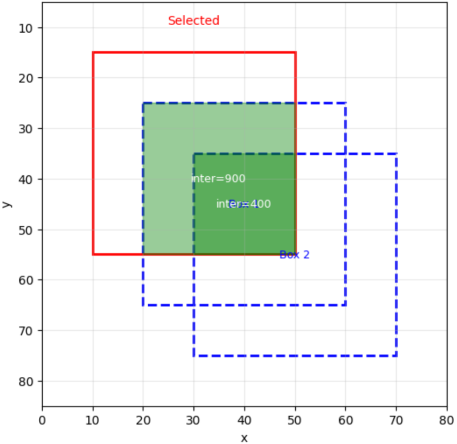

Sigmoid function test:
sigmoid(-2) = 0.1192
sigmoid(-1) = 0.2689
sigmoid(0) = 0.5000
sigmoid(1) = 0.7311
sigmoid(2) = 0.8808


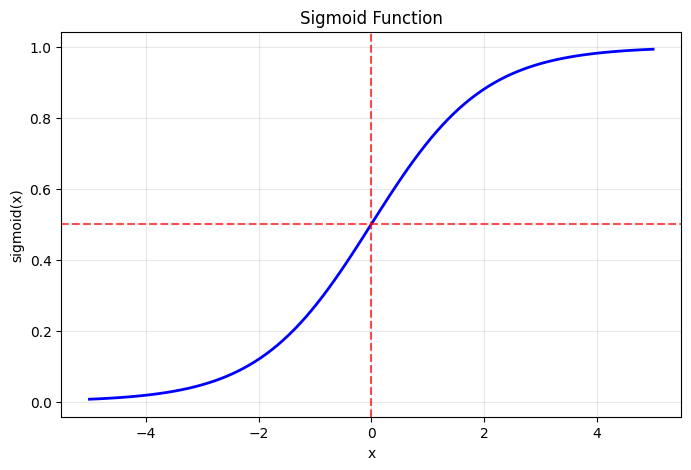

In [6]:
# pose.py에서 사용된 예제: sigmoid 함수와 수학 연산
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# 테스트 데이터
test_values = np.array([-2, -1, 0, 1, 2])
sigmoid_values = sigmoid(test_values)

print("Sigmoid function test:")
for i, (x, s) in enumerate(zip(test_values, sigmoid_values)):
    print(f"sigmoid({x}) = {s:.4f}")

# 시각화
x = np.linspace(-5, 5, 100)
y = sigmoid(x)

plt.figure(figsize=(8, 5))
plt.plot(x, y, 'b-', linewidth=2)
plt.title('Sigmoid Function')
plt.xlabel('x')
plt.ylabel('sigmoid(x)')
plt.grid(True, alpha=0.3)
plt.axhline(y=0.5, color='r', linestyle='--', alpha=0.7)
plt.axvline(x=0, color='r', linestyle='--', alpha=0.7)
plt.show()

## 4. 배열 인덱싱과 슬라이싱

AI 모델의 출력을 처리할 때 자주 사용되는 기능들입니다.

In [7]:
# od_yolo5s_1.py에서 사용된 예제: 배열 슬라이싱
# YOLO 모델 출력 형태를 모방한 데이터
# 실제 코드: ie_output0[i, 0:4], ie_output0[i, 4], ie_output0[i, 5:]

# 가상의 YOLO 출력 (1개 검출 결과)
yolo_output = np.array([320, 240, 100, 80, 0.85, 0.1, 0.9, 0.05])  # [cx, cy, w, h, obj_conf, class1, class2, class3]

# 바운딩 박스 좌표 추출
bbox = yolo_output[0:4]  # 처음 4개 요소
cx, cy, w, h = yolo_output[0:4]  # 개별 변수로 분해

# confidence 점수: 객체가 존재할 확률
obj_conf = yolo_output[4]  # 5번째 요소

# 클래스 확률들
class_confs = yolo_output[5:]  # 6번째부터 끝까지

print("YOLO output analysis:")
print(f"Full output: {yolo_output}")
print(f"Bounding box [cx, cy, w, h]: {bbox}")
print(f"Center point: ({cx}, {cy})")
print(f"Size: {w} x {h}")
print(f"Object confidence: {obj_conf}")
print(f"Class probabilities: {class_confs}")

# 가장 높은 클래스 찾기
class_id = np.argmax(class_confs)
class_score = class_confs[class_id]
final_score = obj_conf * class_score

print(f"\nPredicted class: {class_id}")
print(f"Class score: {class_score:.3f}")
print(f"Final score: {final_score:.3f}")

YOLO output analysis:
Full output: [3.2e+02 2.4e+02 1.0e+02 8.0e+01 8.5e-01 1.0e-01 9.0e-01 5.0e-02]
Bounding box [cx, cy, w, h]: [320. 240. 100.  80.]
Center point: (320.0, 240.0)
Size: 100.0 x 80.0
Object confidence: 0.85
Class probabilities: [0.1  0.9  0.05]

Predicted class: 1
Class score: 0.900
Final score: 0.765


In [8]:
# 2차원 배열에서의 슬라이싱
# pose.py에서 사용된 패턴: kpts[k*3:(k+1)*3]

# 17개 키포인트의 (x, y, confidence) 데이터 시뮬레이션
kpt_count = 5  # 간단히 5개만 사용
kpts = np.random.rand(kpt_count * 3) * 100  # 랜덤 데이터 (random:0~1)*100

print("Original keypoint data:")
print(kpts)
print(f"Total length: {len(kpts)}")

print("\nKeypoint decomposition:")
for k in range(kpt_count):
    start_idx = k * 3
    end_idx = (k + 1) * 3
    kx, ky, kc = kpts[start_idx:end_idx]  # 3개씩 슬라이싱
    print(f"Keypoint {k}: x={kx:.2f}, y={ky:.2f}, conf={kc:.2f}")

Original keypoint data:
[27.66832742 12.67184761 81.40312918 97.34693143 74.16920831 10.4254525
 63.95508514 46.55759159  6.64352445 83.19294046 53.59627491 88.13159269
  8.37842245 77.84702368 43.6661229 ]
Total length: 15

Keypoint decomposition:
Keypoint 0: x=27.67, y=12.67, conf=81.40
Keypoint 1: x=97.35, y=74.17, conf=10.43
Keypoint 2: x=63.96, y=46.56, conf=6.64
Keypoint 3: x=83.19, y=53.60, conf=88.13
Keypoint 4: x=8.38, y=77.85, conf=43.67


## 5. 배열 모양 변경

AI 모델 입출력 처리에서 중요한 배열 형태 변환입니다.

In [9]:
# faceID.py에서 사용된 예제: np.stack(), np.squeeze()

# 여러 텐서를 하나로 합치기 (np.stack)
tensor1 = np.array([1, 2, 3, 4, 5])
tensor2 = np.array([6, 7, 8, 9, 10])
tensor3 = np.array([11, 12, 13, 14, 15])

decoded_tensor = [tensor1, tensor2, tensor3]
stacked = np.stack(decoded_tensor)

print("Individual tensors:")
for i, t in enumerate(decoded_tensor):
    print(f"tensor{i+1}: {t}")

print(f"\nStacked result:")
print(stacked)
print(f"Shape: {stacked.shape}")

# np.squeeze() - 불필요한 차원 제거: 메모리 효율성과 연산 성능을 향상 목적
# 원본 코드: x = np.squeeze(decoded_tensor)
test_array = np.array([[[1, 2, 3, 4, 5]]])  # shape: (1, 1, 5)
squeezed = np.squeeze(test_array)

print(f"\nOriginal array shape: {test_array.shape}")
print(f"After squeeze shape: {squeezed.shape}")
print(f"Original: {test_array}")
print(f"After squeeze: {squeezed}")

Individual tensors:
tensor1: [1 2 3 4 5]
tensor2: [ 6  7  8  9 10]
tensor3: [11 12 13 14 15]

Stacked result:
[[ 1  2  3  4  5]
 [ 6  7  8  9 10]
 [11 12 13 14 15]]
Shape: (3, 5)

Original array shape: (1, 1, 5)
After squeeze shape: (5,)
Original: [[[1 2 3 4 5]]]
After squeeze: [1 2 3 4 5]


In [10]:
# 배열 연결과 분할
# pose.py에서 사용된 예제: np.concatenate

# 두 배열을 연결
arr1 = np.array([1, 2, 3])
arr2 = np.array([4, 5, 6])
concatenated = np.concatenate([arr1, arr2])

print("Array concatenation:")
print(f"arr1: {arr1}")
print(f"arr2: {arr2}")
print(f"Concatenated result: {concatenated}")

# 2차원 배열에서의 연결
box = np.array([[10, 20], [30, 40]])  # 2x2
conf = np.array([[0.9], [0.8]])       # 2x1
label = np.array([[1], [2]])          # 2x1

# axis=1로 열 방향 연결
combined = np.concatenate((box, conf, label), axis=1)

print("\n2D array concatenation:")
print(f"box shape: {box.shape}")
print(f"conf shape: {conf.shape}")
print(f"label shape: {label.shape}")
print(f"combined shape: {combined.shape}")
print("Combined result:")
print(combined)

Array concatenation:
arr1: [1 2 3]
arr2: [4 5 6]
Concatenated result: [1 2 3 4 5 6]

2D array concatenation:
box shape: (2, 2)
conf shape: (2, 1)
label shape: (2, 1)
combined shape: (2, 4)
Combined result:
[[10.  20.   0.9  1. ]
 [30.  40.   0.8  2. ]]


## 6. 선형대수 연산

AI에서 중요한 벡터와 행렬 연산들입니다.

In [11]:
# faceID.py에서 사용된 예제: 코사인 유사도 계산
# 원본 코드: return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6)

def cosine_similarity(a, b):
    """Calculates cosine similarity between two vectors"""
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-6)

# 얼굴 특징 벡터 시뮬레이션 (512차원)
face_feature1 = np.random.rand(512)
face_feature2 = np.random.rand(512)
face_feature3 = face_feature1 + np.random.rand(512) * 0.1  # 비슷한 특징

# 유사도 계산
sim1_2 = cosine_similarity(face_feature1, face_feature2)
sim1_3 = cosine_similarity(face_feature1, face_feature3)
sim1_1 = cosine_similarity(face_feature1, face_feature1)  # 자기 자신

print("Cosine similarity calculation results:")
print(f"Face1 vs Face2 (random): {sim1_2:.4f}")
print(f"Face1 vs Face3 (similar): {sim1_3:.4f}")
print(f"Face1 vs Face1 (identical): {sim1_1:.4f}")

# 각 연산의 의미 설명
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])

dot_product = np.dot(a, b)  # 내적
norm_a = np.linalg.norm(a)  # L2 노름 (벡터의 크기)
norm_b = np.linalg.norm(b)

print(f"\nVector operation example:")
print(f"Vector a: {a}")
print(f"Vector b: {b}")
print(f"Dot product: {dot_product}")
print(f"L2 norm of a: {norm_a:.4f}")
print(f"L2 norm of b: {norm_b:.4f}")
print(f"Cosine similarity: {dot_product / (norm_a * norm_b):.4f}")

Cosine similarity calculation results:
Face1 vs Face2 (random): 0.7620
Face1 vs Face3 (similar): 0.9985
Face1 vs Face1 (identical): 1.0000

Vector operation example:
Vector a: [1 2 3]
Vector b: [4 5 6]
Dot product: 32
L2 norm of a: 3.7417
L2 norm of b: 8.7750
Cosine similarity: 0.9746


In [12]:
# 다른 유용한 선형대수 연산들

# 행렬 곱셈
matrix_a = np.array([[1, 2], [3, 4]])
matrix_b = np.array([[5, 6], [7, 8]])
matrix_mult = np.matmul(matrix_a, matrix_b)  # 또는 matrix_a @ matrix_b

print("Matrix multiplication:")
print(f"Matrix A:\n{matrix_a}")
print(f"Matrix B:\n{matrix_b}")
print(f"A × B:\n{matrix_mult}")

# 전치행렬
transposed = matrix_a.T
print(f"\nTranspose of A:\n{transposed}")

# 역행렬 (가능한 경우)
try:
    inverse = np.linalg.inv(matrix_a)
    print(f"\nInverse of A:\n{inverse}")
    
    # 검증: A × A^(-1) = I (단위행렬)
    identity_check = np.matmul(matrix_a, inverse)
    print(f"\nA × A^(-1) (should be identity matrix):\n{identity_check}")
except np.linalg.LinAlgError:
    print("\nInverse matrix does not exist.")

Matrix multiplication:
Matrix A:
[[1 2]
 [3 4]]
Matrix B:
[[5 6]
 [7 8]]
A × B:
[[19 22]
 [43 50]]

Transpose of A:
[[1 3]
 [2 4]]

Inverse of A:
[[-2.   1. ]
 [ 1.5 -0.5]]

A × A^(-1) (should be identity matrix):
[[1.0000000e+00 0.0000000e+00]
 [8.8817842e-16 1.0000000e+00]]
